In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
import numba as nb

totalNum = 369
delta = 1e-2
coordStep = 12.5
atomicUnit = 0.05292
energyUnitConversion = 27.2114
mass = 0.067 # atomicUnit
hBar = 1 # atomicUnit
batteOfGrunwaldDate = 1410
globalNum, xCoordNano, yCoordNano, boxPosition = np.loadtxt("data/11.dat", unpack = True)
boxPositionMapping = {"inside": 0, "lr edge": 1, "bottom edge": 2, "top edge": 3}
cellNum, localNum, globalNum2 = np.loadtxt("data/19.dat", unpack = True)

In [2]:
# Laplace potential

@nb.njit
def get_p(index):
  match index:
    case 1:
      p = - np.sqrt(3/7 - 2/7 * np.sqrt(6/5))
    case 2:
      p = np.sqrt(3/7 - 2/7 * np.sqrt(6/5))
    case 3:
      p = np.sqrt(3/7 + 2/7 * np.sqrt(6/5))
    case 4:
      p = - np.sqrt(3/7 + 2/7 * np.sqrt(6/5))
  return p

@nb.njit
def get_w(index):
  match index:
    case 1 | 2:
      w = (18 + np.sqrt(30)) / 36
    case 3 | 4:
      w = (18 - np.sqrt(30)) / 36
  return w

@nb.njit
def get_global_coord_from_local(epsilon1, epsilon2, k):
  xGlobal, yGlobal = 0, 0
  for i in range(1, 4 + 1):
    xGlobal += get_g_shape_function(i, epsilon1, epsilon2) * map_k_and_i_to_global_coord(k, i, "x")
    yGlobal += get_g_shape_function(i, epsilon1, epsilon2) * map_k_and_i_to_global_coord(k, i, "y")
  return xGlobal, yGlobal

@nb.njit
def map_k_and_i_to_global_coord(k, i, coord):
  searchedglobalNum = np.where( (cellNum == k) & (localNum == i) )[0][0]
  match coord:
    case "x":
      global_coord = xCoordNano[int(globalNum2[searchedglobalNum]) - 1]
    case "y":
      global_coord = yCoordNano[int(globalNum2[searchedglobalNum]) - 1]
  return global_coord

@nb.njit
def get_g_shape_function(index, epsilon1, epsilon2):
  f1 = lambda e: .5 * (1 - e)
  f2 = lambda e: .5 * (1 + e)
  match index:
    case 1:
      shapeFunction = f1(epsilon1) * f1(epsilon2)
    case 2:
      shapeFunction = f2(epsilon1) * f1(epsilon2)
    case 3:
      shapeFunction = f1(epsilon1) * f2(epsilon2)
    case 4:
      shapeFunction = f2(epsilon1) * f2(epsilon2)
  return shapeFunction

@nb.njit
def get_local_potential_or_WF(k, i, potentialsOrEigenvalues):
  Mask = (cellNum == k) & (localNum == i)
  index = globalNum2[Mask][0]
  return potentialsOrEigenvalues[int(index) - 1]

@nb.njit
def get_global_potential_or_wave_function_from_local(epsilon1, epsilon2, k, potentialsOrEigenvalues):
  returnValue = 0
  for i in range(1, 9 + 1):
    returnValue += get_h_shape_function(i, epsilon1, epsilon2) * get_local_potential_or_WF(k, i, potentialsOrEigenvalues)
  return returnValue

@nb.njit
def get_h_shape_function(index, epsilon1, epsilon2):
  q1 = lambda e: .5 * e * (e - 1)
  q2 = lambda e: (1 - e) * (1 + e)
  q3 = lambda e: .5 * e * (1 + e)
  match index:
    case 1:
      shapeFunction = q1(epsilon1) * q1(epsilon2)
    case 2:
      shapeFunction = q3(epsilon1) * q1(epsilon2)
    case 3:
      shapeFunction = q1(epsilon1) * q3(epsilon2)
    case 4:
      shapeFunction = q3(epsilon1) * q3(epsilon2)
    case 5:
      shapeFunction = q2(epsilon1) * q1(epsilon2)
    case 6:
      shapeFunction = q3(epsilon1) * q2(epsilon2)
    case 7:
      shapeFunction = q1(epsilon1) * q2(epsilon2)
    case 8:
      shapeFunction = q2(epsilon1) * q3(epsilon2)
    case 9:
      shapeFunction = q2(epsilon1) * q2(epsilon2)
  return shapeFunction

@nb.njit
def fill_global_matrix_T(T):
  tLocalMatrix = get_local_matrix_t()
  for k in range(0, len(cellNum), 9):
    for il1 in range(9):
      for il2 in range(9):
        T[ int(globalNum2[k+il1]) - 1 ][ int(globalNum2[k+il2]) - 1 ] += tLocalMatrix[il1, il2]
  return None

@nb.njit
def get_local_matrix_t():
  tLocal = np.zeros((9, 9))
  for il1 in range(9):
    for il2 in range(9):
      tLocal[il1, il2] = get_local_t_element(il1 + 1, il2 + 1)
  return tLocal

@nb.njit
def get_local_t_element(i, j):
  t = 0
  for l in range(1, 4 + 1):
    for n in range(1, 4 + 1):
      coord1 = get_p(l)
      coord2 = get_p(n)
      weight = get_w(l) * get_w(n)
      dhi_deps1 = derive_h("first", i, coord1, coord2)
      dhi_deps2 = derive_h("second", i, coord1, coord2)
      dhj_deps1 = derive_h("first", j, coord1, coord2)
      dhj_deps2 = derive_h("second", j, coord1, coord2)
      t += weight * (dhj_deps1 * dhi_deps1 + dhi_deps2 * dhj_deps2)
  return t

@nb.njit
def derive_h(whichCoord, whichIndex, coord1, coord2):
  match whichCoord:
    case "first":
      returnValue = .5 * (get_h_shape_function(whichIndex, coord1 + delta, coord2) - get_h_shape_function(whichIndex, coord1 - delta, coord2)) / delta
    case "second":
      returnValue = .5 * (get_h_shape_function(whichIndex, coord1, coord2 + delta) - get_h_shape_function(whichIndex, coord1, coord2 - delta)) / delta
  return returnValue

def set_T_and_p_boundaries(T, p, Vtop, Vbottom):
  ymin, ymax = get_ymin_and_ymax()
  for i in range(totalNum):
    match boxPosition[i]:
      case 0:
        p[i] = 0
      case 1:
        p[i] = ( yCoordNano[i] - ymin ) / ( 0 - ymin ) * ( Vtop - Vbottom ) + Vbottom
        T[i, :] = 0
        T[i, i] = 1
      case 2:
        p[i] = Vbottom
        T[i, :] = 0
        T[i, i] = 1
      case 3:
        p[i] = Vtop
        T[i, :] = 0
        T[i, i] = 1
  return None

def get_ymin_and_ymax():
  mask = boxPosition == boxPositionMapping["lr edge"]
  ymin = np.min(yCoordNano[mask])
  ymax = np.max(yCoordNano[mask])
  return ymin - .5 * coordStep, ymax + .5 * coordStep

def get_node_potentials(Vtop, Vbottom):
  T, p = np.zeros((totalNum, totalNum)), np.zeros(totalNum)
  fill_global_matrix_T(T,)
  set_T_and_p_boundaries(T, p, Vtop, Vbottom)
  return np.linalg.solve(T, p)

def get_refined_mesh(potentialsOrEigenvalues, numberOfNewNodes1dim):
  eps1 = np.linspace(-1, 1, numberOfNewNodes1dim+2)
  eps2 = np.linspace(-1, 1, numberOfNewNodes1dim+2)
  newPotentialsOrEigenvalues = potentialsOrEigenvalues.copy()
  newXCoordNano = xCoordNano.copy()
  newYCoordNano = yCoordNano.copy()
  for kIndex in range(1, len(cellNum), 9):
    for e1 in eps1:
      for e2 in eps2:
        if (e1 == -1 or e1 == 0 or e1 == 1) and (e2 == -1 or e2 == 0 or e2 == 1):
          continue
        else:
          newPotentialsOrEigenvalues = np.append(newPotentialsOrEigenvalues, get_global_potential_or_wave_function_from_local(e1, e2, cellNum[kIndex], potentialsOrEigenvalues))
          newX, newY = get_global_coord_from_local(e1, e2, cellNum[kIndex])
          newXCoordNano = np.append(newXCoordNano, newX)
          newYCoordNano = np.append(newYCoordNano, newY)
  return newPotentialsOrEigenvalues, newXCoordNano, newYCoordNano


In [3]:
# TESTS
print(globalNum.shape[0] == xCoordNano.shape[0] == yCoordNano.shape[0] == boxPosition.shape[0] == 369)
print(cellNum.shape[0] == localNum.shape[0] == globalNum2.shape[0] == 720)
print(globalNum.dtype, xCoordNano.dtype, yCoordNano.dtype, boxPosition.dtype)
print(cellNum.dtype, localNum.dtype, globalNum2.dtype)
print(type(globalNum))
print(globalNum[0] == 1)

print((x1:= map_k_and_i_to_global_coord(80, 2, "x")) == 25.0)
print((y1:= map_k_and_i_to_global_coord(80, 2, "y")) == 37.5)
x2, y2 = get_global_coord_from_local(-0.5, -0.5, 80)
print(x2 == x1 - 2 * 6.25 * .75, y2 == y1 + 2 * 6.25 * .25)


True
True
float64 float64 float64 float64
float64 float64 float64
<class 'numpy.ndarray'>
True
True
True
True True


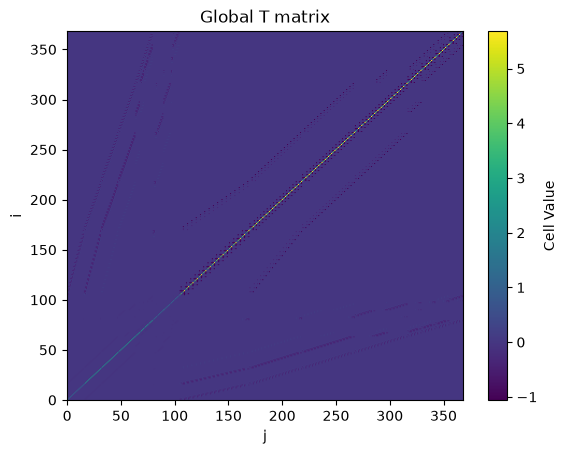

In [4]:
T = np.zeros((totalNum, totalNum))
fill_global_matrix_T(T)

plt.figure()
plt.imshow(T, origin='lower', aspect='auto')
plt.colorbar(label='Cell Value')
plt.xlabel('j')
plt.ylabel('i')
plt.title('Global T matrix')
plt.show()

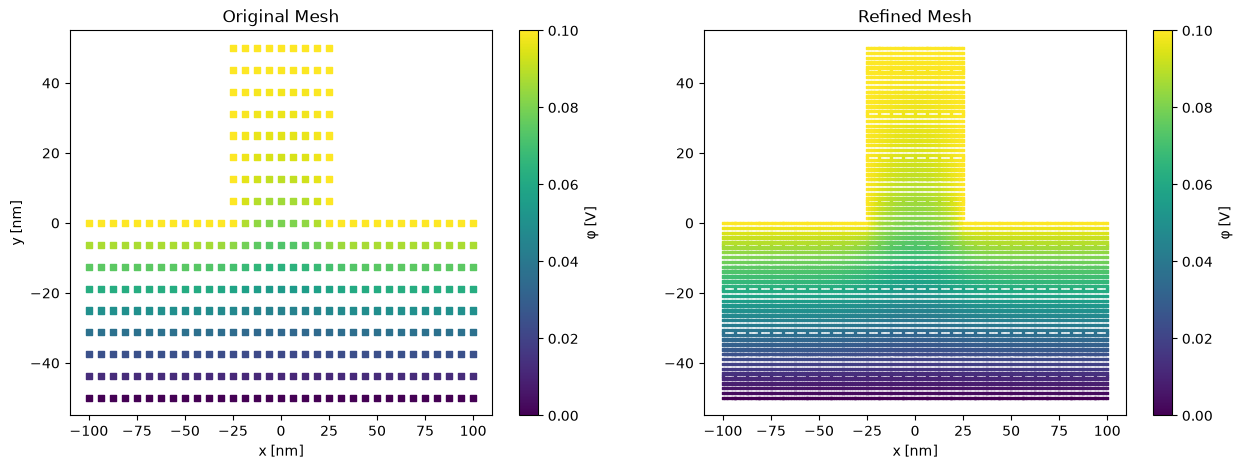

In [5]:
potential = get_node_potentials(Vtop = 0.1, Vbottom = 0)
NewPotentials, newXCoordNano, newYCoordNano = get_refined_mesh(potential, 8)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
scatter0 = ax[0].scatter(xCoordNano, yCoordNano, c=potential, marker="s", s=20)
scatter1 = ax[1].scatter(newXCoordNano, newYCoordNano, c=NewPotentials, marker="s", s=3)
fig.colorbar(scatter0, ax=ax[0], label="φ [V]")
fig.colorbar(scatter1, ax=ax[1], label="φ [V]")
plt.title("Node Potentials Distribution")
ax[0].set_title("Original Mesh")
ax[1].set_title("Refined Mesh")
ax[0].set_xlabel("x [nm]")
ax[1].set_xlabel("x [nm]")
ax[0].set_ylabel("y [nm]")
plt.show()

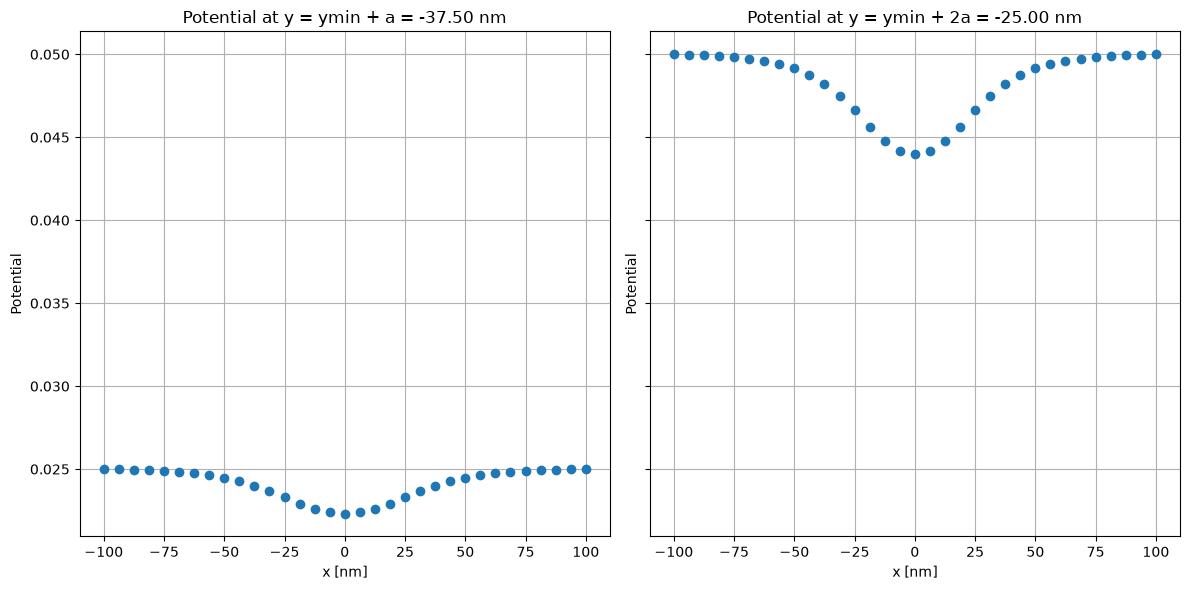

In [6]:
ymin, ymax = get_ymin_and_ymax()
maskA = yCoordNano == ymin + coordStep
mask2A = yCoordNano == ymin + 2 * coordStep
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].plot(xCoordNano[maskA], potential[maskA], 'o')
ax[0].set_title(f'Potential at y = ymin + a = {ymin + coordStep:.2f} nm')
ax[0].set_xlabel('x [nm]')
ax[0].set_ylabel('Potential')
ax[0].grid()
ax[1].plot(xCoordNano[mask2A], potential[mask2A], 'o')
ax[1].set_title(f'Potential at y = ymin + 2a = {ymin + 2 * coordStep:.2f} nm')
ax[1].set_xlabel('x [nm]')
ax[1].set_ylabel('Potential')
ax[1].grid()
plt.tight_layout()
plt.show()

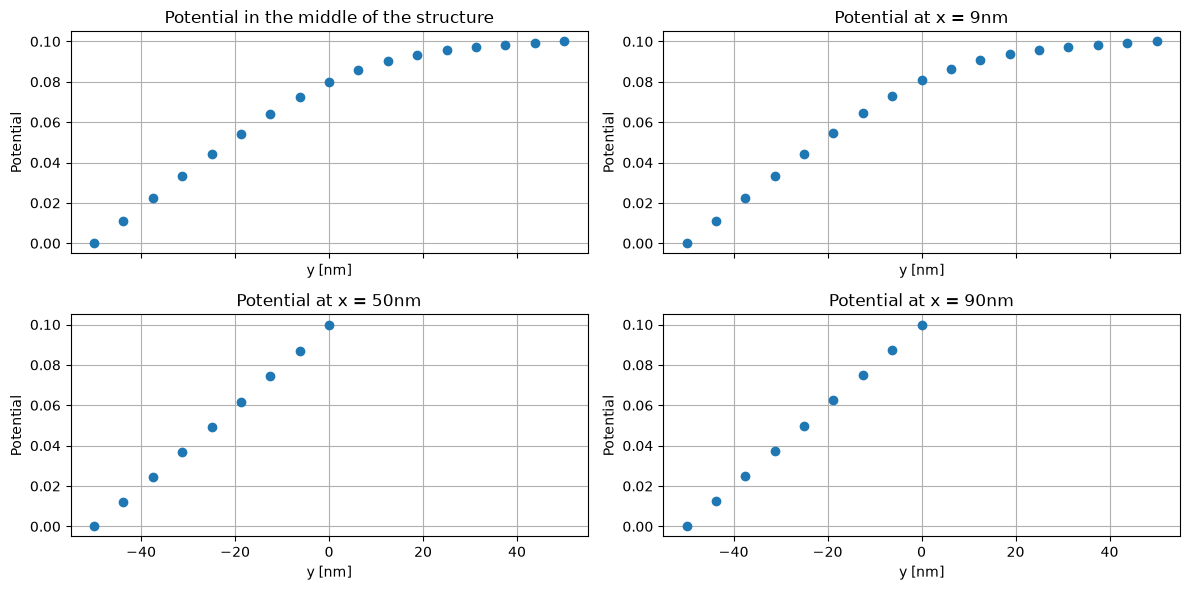

In [7]:
xmin, xmax = np.min(xCoordNano), np.max(xCoordNano)
deltaX0 = round(( .5 * ( xmax + xmin ) - xmin ) / ( .5 * coordStep ))
Mask0 = (abs(xCoordNano - (xmin + deltaX0 * .5 * coordStep)) < 0.25 * coordStep)
Mask1 = (abs(xCoordNano - 9) < 0.25 * coordStep)
Mask2 = (abs(xCoordNano - 50) < 0.25 * coordStep)
Mask3 = (abs(xCoordNano - 90) < 0.25 * coordStep)
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
ax[0][0].plot(yCoordNano[Mask0], potential[Mask0], 'o')
ax[0][0].set_title('Potential in the middle of the structure')
ax[0][0].set_xlabel('y [nm]')
ax[0][0].set_ylabel('Potential')
ax[0][0].grid()

ax[0][1].plot(yCoordNano[Mask1], potential[Mask1], 'o')
ax[0][1].set_title('Potential at x = 9nm')
ax[0][1].set_xlabel('y [nm]')
ax[0][1].set_ylabel('Potential')
ax[0][1].grid()

ax[1][0].plot(yCoordNano[Mask2], potential[Mask2], 'o')
ax[1][0].set_title('Potential at x = 50nm')
ax[1][0].set_xlabel('y [nm]')
ax[1][0].set_ylabel('Potential')
ax[1][0].grid()

ax[1][1].plot(yCoordNano[Mask3], potential[Mask3], 'o')
ax[1][1].set_title('Potential at x = 90nm')
ax[1][1].set_xlabel('y [nm]')
ax[1][1].set_ylabel('Potential')
ax[1][1].grid()

plt.tight_layout()
plt.show()

print()

In [8]:
# Schrodinger equation

@nb.njit
def get_local_matrix_s():
    sLocal = np.zeros((9, 9))
    for i in range(9):
        for j in range(9):
            sLocal[i, j] = get_local_s_element(i + 1, j + 1)
    return sLocal

@nb.njit
def get_local_s_element(i, j):
    s_jik = 0
    for l in range(1, 4 + 1):
        for n in range(1, 4 + 1):
            coord1 = get_p(l)
            coord2 = get_p(n)
            weight = get_w(l) * get_w(n)
            h_j = get_h_shape_function(j, coord1, coord2)
            h_i = get_h_shape_function(i, coord1, coord2)
            s_jik += weight * h_j * h_i
    return s_jik * coordStep * coordStep * 0.25

@nb.njit
def get_local_matrix_kinetic():
    tLocal = get_local_matrix_t()
    return ( hBar * hBar * tLocal / (2 * mass) * ( atomicUnit * atomicUnit ) ) * energyUnitConversion

@nb.njit
def get_local_potential_element(i, j, k, potentials):
    v_jik = 0
    for l in range(1, 4 + 1):
        for n in range(1, 4 + 1):
            coord1 = get_p(l)
            coord2 = get_p(n)
            weight = get_w(l) * get_w(n)
            h_j = get_h_shape_function(j, coord1, coord2)
            h_i = get_h_shape_function(i, coord1, coord2)
            v_jik += weight * h_j * h_i * get_global_potential_or_wave_function_from_local(coord1, coord2, k, potentials)
    return v_jik * coordStep * coordStep * 0.25

@nb.njit
def get_local_matrix_potential(k, potentials):
    vLocal = np.zeros((9, 9))
    for i in range(9):
        for j in range(9):
            vLocal[i, j] = get_local_potential_element(i + 1, j + 1, k, potentials)
    return vLocal

@nb.njit
def fill_global_matrices_S_and_H(S, H, potentials):
    sLocalMatrix = get_local_matrix_s()
    kLocalMatrix = get_local_matrix_kinetic()
    for k in range(0, len(cellNum), 9):
        vLocalMatrix = get_local_matrix_potential(cellNum[k], potentials)
        for il1 in range(9):
            for il2 in range(9):
                S[int(globalNum2[k + il1]) - 1][int(globalNum2[k + il2]) - 1] += sLocalMatrix[il1, il2]
                H[int(globalNum2[k + il1]) - 1][int(globalNum2[k + il2]) - 1] += kLocalMatrix[il1, il2] + vLocalMatrix[il1, il2]
    return None

def set_S_and_H_boundaries(S, H):
    for i in range(totalNum):
        match boxPosition[i]:
            case 0:
                pass
            case 1 | 2 | 3:
                S[i, :] = 0
                S[:, i] = 0
                H[i, :] = 0
                H[:, i] = 0
                S[i, i] = 1
                H[i, i] = -batteOfGrunwaldDate
    return None

def get_node_eigenvalues_and_eigenvectors(potentials):
    S, H = np.zeros((totalNum, totalNum)), np.zeros((totalNum, totalNum))
    fill_global_matrices_S_and_H(S, H, potentials)
    set_S_and_H_boundaries(S, H)
    eigenvalues, eigenvectors = eigh(H, S)
    return eigenvalues, eigenvectors


In [9]:
def plot_4_states_and_get_energy(Vtop, Vbottom, plot):
    potential = get_node_potentials(Vtop, Vbottom)
    eigenvalues, eigenvectors = get_node_eigenvalues_and_eigenvectors(potential)
    firstIndex = np.where(eigenvalues > 0)[0][0]
    optimalEigenvalues, optimalEigenvectors = eigenvalues[firstIndex:], eigenvectors[:, firstIndex:]
    if plot:
        fig, ax = plt.subplots(4, 2, figsize=(20, 15))
        for i in range(4):
            waveFunction, newXCoordNano, newYCoordNano = get_refined_mesh(optimalEigenvectors[:, i], 12)
            scatter0 = ax[i][0].scatter(xCoordNano, yCoordNano, c=optimalEigenvectors[:, i], marker="s", s=20)
            scatter1 = ax[i][1].scatter(newXCoordNano, newYCoordNano, c=waveFunction, marker="s", s=3)
            fig.colorbar(scatter0, ax=ax[i][0], label=f"φ state {i + 1}")
            fig.colorbar(scatter1, ax=ax[i][1], label=f"φ state {i + 1}")
            plt.title("Wave Function")
            ax[i][0].set_title(f"Original Mesh state {i + 1}")
            ax[i][1].set_title(f"Refined Mesh state {i + 1}")
            ax[i][0].set_xlabel("x [nm]")
            ax[i][1].set_xlabel("x [nm]")
            ax[i][0].set_ylabel("y [nm]")
        plt.tight_layout()
        plt.show()
    return optimalEigenvalues[:4]

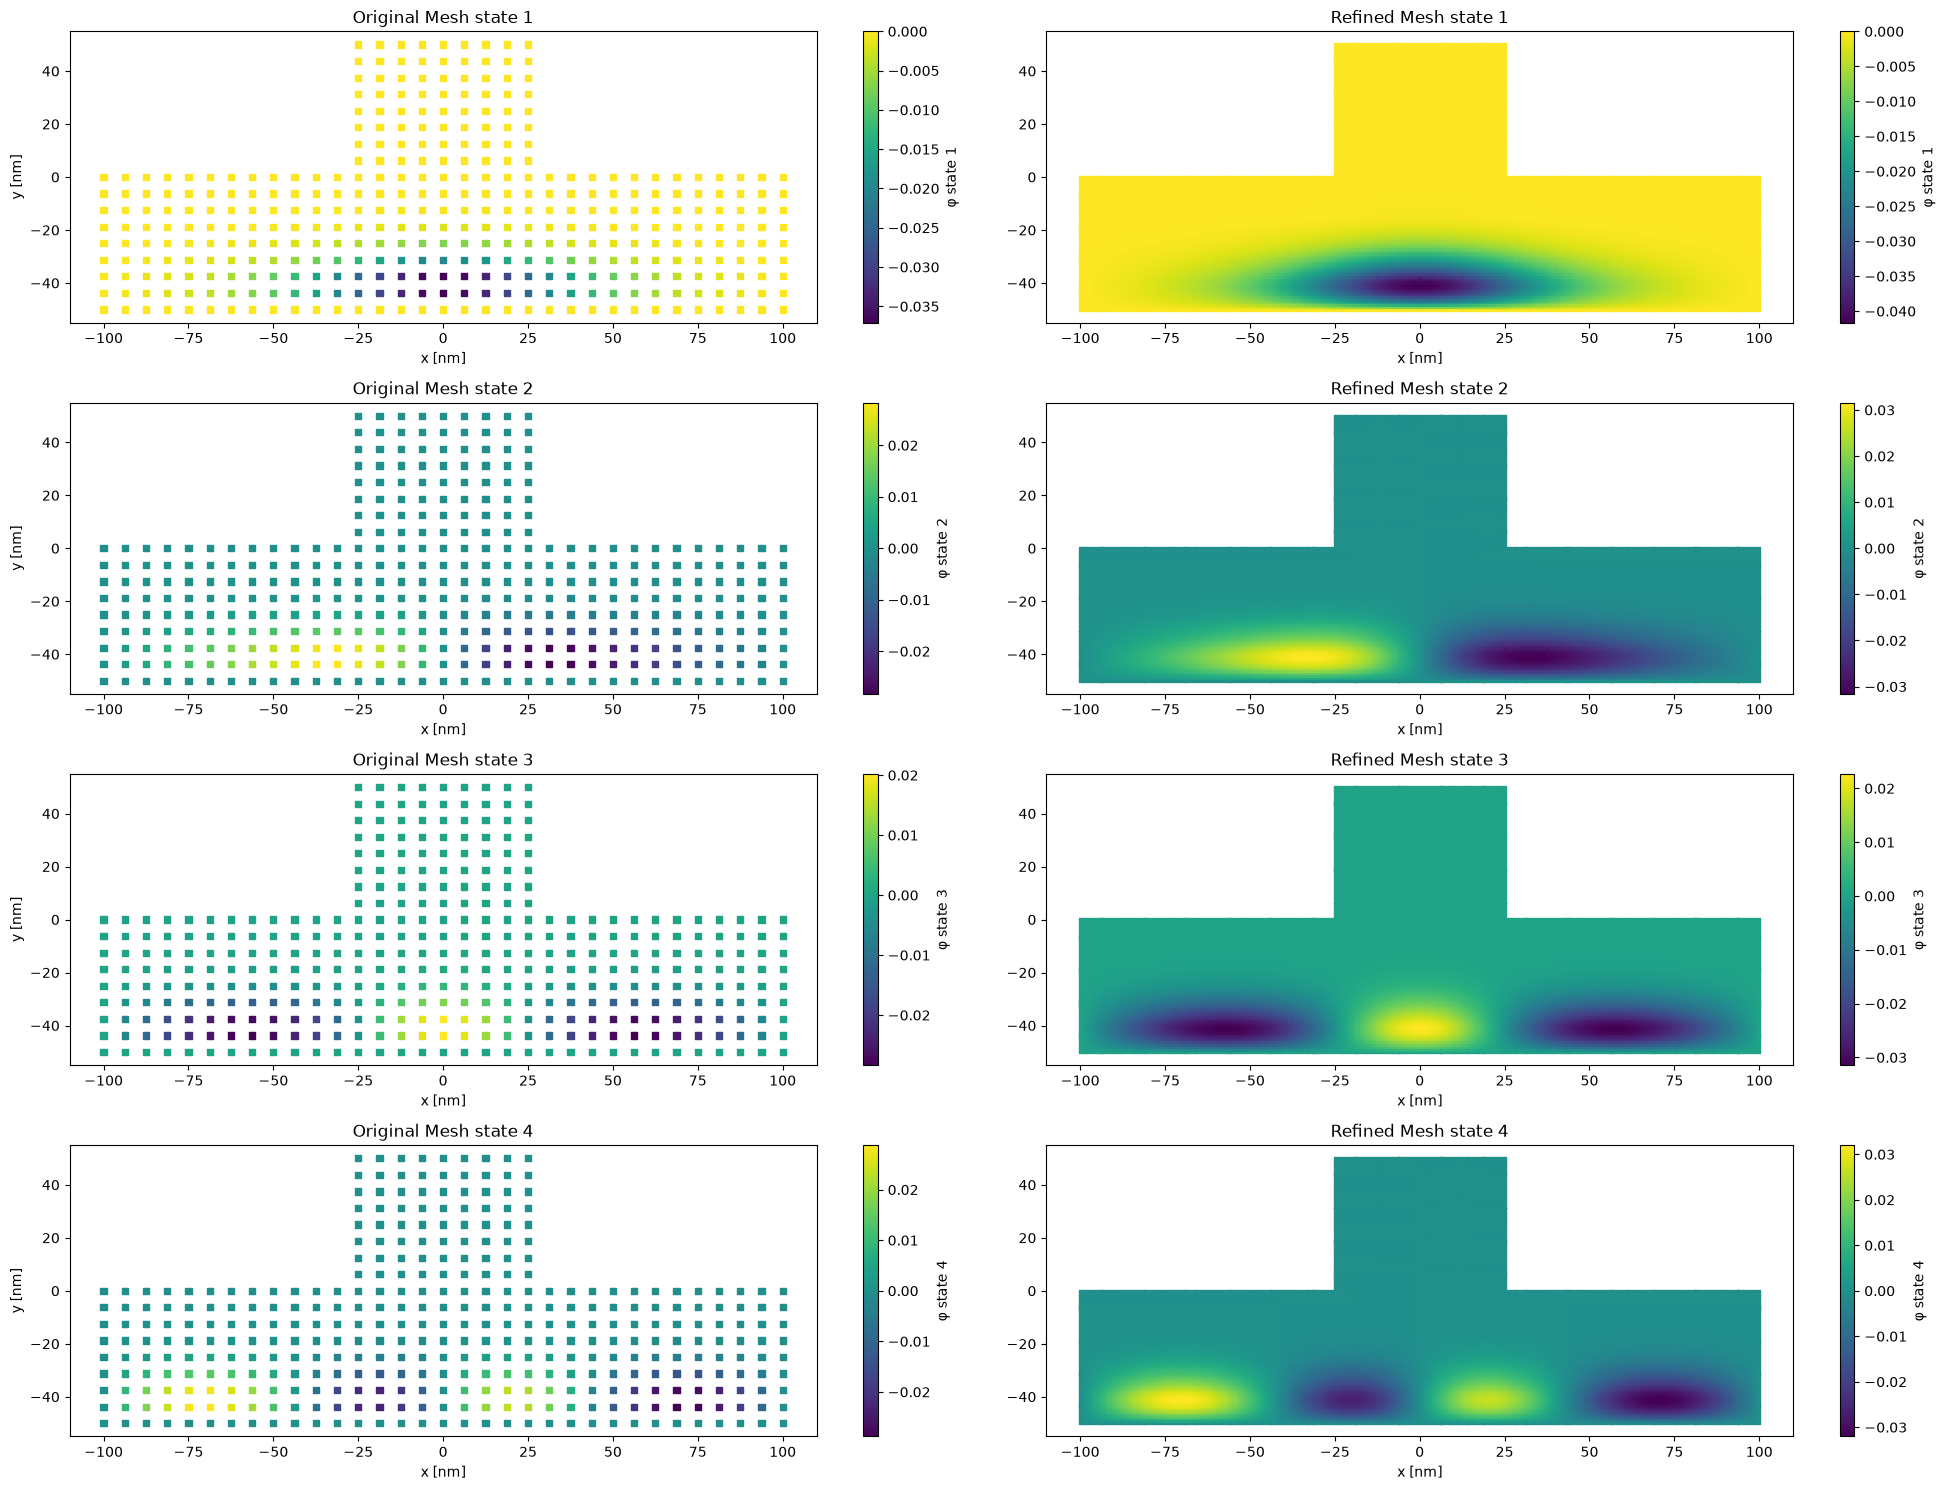

In [12]:
potentialsOfTop = np.linspace(0.1, 1, 10)
energiesOf4States = np.zeros((10, 4))
energiesOf4States[0, :] = plot_4_states_and_get_energy(0.1, 0, True)
for i in range(1, 10):
    energiesOf4States[i, :] = plot_4_states_and_get_energy(potentialsOfTop[i], 0, False)



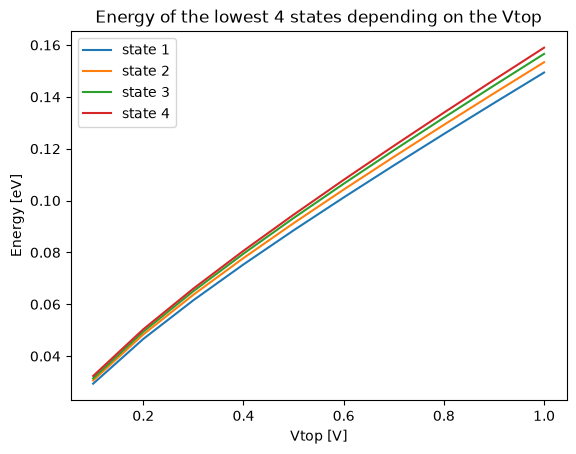

In [15]:
for j in range(4):
    plt.plot(potentialsOfTop, energiesOf4States[:, j], label=f"state {j+1}")
plt.title("Energy of the lowest 4 states depending on the Vtop")
plt.xlabel('Vtop [V]')
plt.ylabel('Energy [eV]')
plt.legend()
plt.show()